# Settings

In [201]:
file_path1 = "./data_nsi/csv/beamformed/000_test1_angle0_env_nsi.npy"
file_path2 = "./data_nsi/csv/beamformed/000_test1_angle0_rectangle.npy"

visualizing_upsampled_data = True

# Imports

In [202]:
import numpy as np
import matplotlib.pyplot as plt
import json

# Import parameters

In [203]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

def calculate_variables(params):
    array_length = params["array"]["length"] #transducer array length
    frequency = params["wave"]["frequency"] #hz
    c = params["wave"]["c"] #speed of sound in m/s
    sampling_rate = params["wave"]["sampling_rate"] #1/s = 16 * frequency
    total_depth = params["simulation"]["total_depth"] #total depth in m
    pitch = params["array"]["pitch"] #pitch in m
    interpolation_factor = params["simulation"]["interpolation_factor"] #interpolation factor   
    
    step_size = 1 / sampling_rate #cuz frequency = 1 / T 
    samples = int(sampling_rate * (total_depth / c)) #sampling rate 1/s * total depth m / (m/s) = samples - samples needed to cover the total depth
    upsampled_samples = samples + (interpolation_factor - 1) * (samples - 1)
    upsampled_step_size = step_size / interpolation_factor
    
    pos = np.linspace(start=0, stop=array_length, num=array_length, dtype=int) #array position sampling
    time = np.linspace(start=0, stop=step_size * samples, num=samples) #time sampling
    
    params["simulation"]["step_size"] = step_size #step size in s
    params["simulation"]["samples"] = samples
    params["simulation"]["upsampled_samples"] = upsampled_samples
    params["simulation"]["upsampled_sampling_rate"] = sampling_rate * interpolation_factor
    params["simulation"]["upsampled_step_size"] = upsampled_step_size
    
    #more info
    params["simulation"]["maximal_acquisition_depth"] = c * (step_size * samples) / 2 #maximal acquisition depth in m
    params["simulation"]["lateral_step"] = (array_length * pitch) * (1 / params['simulation']['lateral_resolution'])

    
    print("Aperture: ", params["array"]["aperture"])
    print("Samples: ", samples)
    print("Upsampled samples: ", upsampled_samples)
    print("Step size: ", step_size, "s")
    print("Upsampled step size: ", upsampled_step_size, "s")
    print("Maximal acquisition depth:", params["simulation"]["maximal_acquisition_depth"], "m")
    print("Lateral step: ", params["simulation"]["lateral_step"], "m")
    
    return params, pos, time

In [204]:
parameters = load_parameters("./parameters.json")
params, pos, time = calculate_variables(parameters)

Aperture:  0.8
Samples:  833
Upsampled samples:  3329
Step size:  1.6e-08 s
Upsampled step size:  4e-09 s
Maximal acquisition depth: 0.009996 m
Lateral step:  2.25e-05 m


In [205]:
step_size = params["simulation"]["upsampled_step_size"] if visualizing_upsampled_data else params["simulation"]["step_size"]

# Import bf image

In [206]:
bf_matrix1  = np.load(file_path1)
bf_matrix2  = np.load(file_path2)

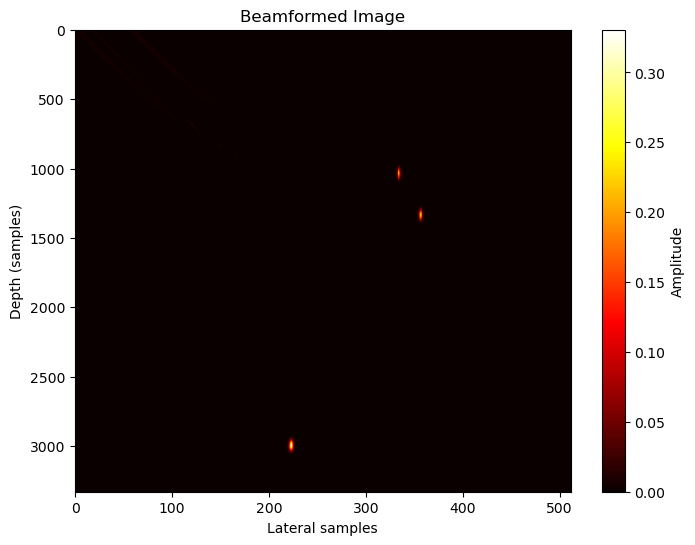

In [207]:
plt.figure(figsize=(8, 6))
plt.imshow(np.abs(bf_matrix1), cmap='hot', aspect='auto')
plt.title("Beamformed Image")
plt.xlabel("Lateral samples")
plt.ylabel("Depth (samples)")
plt.colorbar(label="Amplitude")
plt.show()

# Get high energy zone

In [208]:
def extract_highest_value_region(bf_matrix, submatrix_size=100):
    row, col = np.unravel_index(np.argmax(np.abs(bf_matrix)), bf_matrix.shape)
    
    half_size = int(submatrix_size/2)
    row_start = row - half_size if row - half_size >= 0 else 0
    row_end = row + half_size if row + half_size < bf_matrix.shape[0] else bf_matrix.shape[0]
    col_start = col - half_size if col - half_size >= 0 else 0
    col_end = col + half_size if col + half_size < bf_matrix.shape[1] else bf_matrix.shape[1]

    return bf_matrix[row_start:row_end, col_start:col_end]

In [209]:
high_energy_zone = extract_highest_value_region(bf_matrix1, submatrix_size=120)
print("High energy zone shape: ", high_energy_zone.shape)

High energy zone shape:  (120, 120)


# Visualize lobes

In [210]:
selected_res_zone = high_energy_zone

In [211]:
max_val_row, max_val_col = np.unravel_index(np.argmax(np.abs(selected_res_zone)), selected_res_zone.shape) #max value position

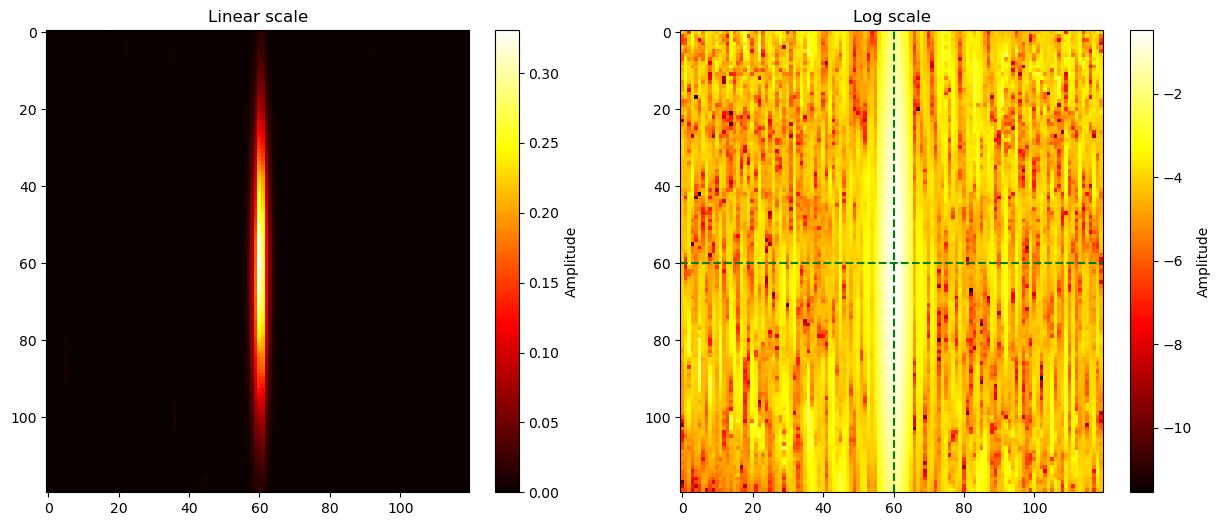

In [212]:
fig, ax = plt.subplots(1,2, figsize=(15, 6))
im0 = ax[0].imshow(np.abs(selected_res_zone), cmap='hot', aspect='auto')
ax[0].set_title("Linear scale")
plt.colorbar(im0, label="Amplitude", ax=ax[0])
im1 = ax[1].imshow(np.log10(np.abs(selected_res_zone)), cmap='hot', aspect='auto')
ax[1].set_title("Log scale")
ax[1].axhline(y=max_val_row, color='g', linestyle='--')
ax[1].axvline(x=max_val_col, color='g', linestyle='--')
plt.colorbar(im1, label="Amplitude", ax=ax[1])
plt.show()

# Metrics

In [213]:
def calculate_resolution(function):
    half_max = -6 #dB
    left_idx = np.where(function >= half_max)[0][0] #first point where the profile is greater than half max
    right_idx = np.where(function >= half_max)[0][-1] #last point where the profile is greater than half max
    return left_idx, right_idx, right_idx - left_idx

## Lateral res (horizontal)

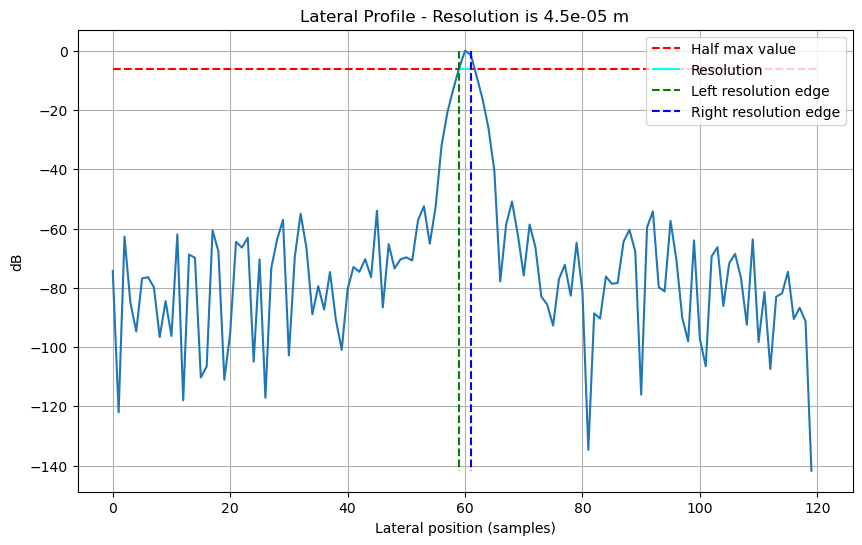

In [214]:
lateral_profile =  20 * np.log10(np.abs(selected_res_zone[max_val_row, :]) / np.max(np.abs(selected_res_zone[max_val_row, :]))) #we take values along the row with maximum value

lat_left_idx, lat_right_idx, lat_res = calculate_resolution(lateral_profile)

plt.figure(figsize=(10, 6))
plt.plot(lateral_profile)
plt.title(f"Lateral Profile - Resolution is {lat_res * params['simulation']['lateral_step']} m")
plt.xlabel("Lateral position (samples)")
plt.ylabel("dB")
plt.grid(True)
plt.hlines(-6, 0, lateral_profile.shape[0], colors='r', linestyles='--', label='Half max value')
plt.hlines(-6, lat_left_idx, lat_right_idx, colors='cyan', linestyles='-', label=f'Resolution')
plt.vlines(lat_left_idx, 0, min(lateral_profile), colors='g', linestyles='--', label='Left resolution edge')
plt.vlines(lat_right_idx, 0, min(lateral_profile), colors='b', linestyles='--', label='Right resolution edge')
plt.legend()
plt.show()

## Axial resolution (vertical)

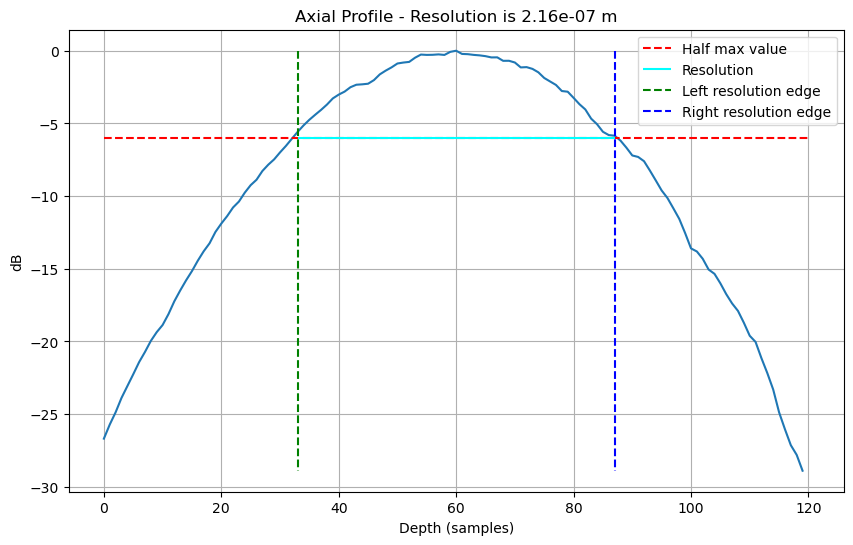

In [215]:
axial_profile = 20 * np.log10(np.abs(selected_res_zone[:, max_val_col]) / np.max(np.abs(selected_res_zone[:, max_val_col]))) #we take values along the column with maximum value

ax_left_idx, ax_right_idx, ax_res = calculate_resolution(axial_profile)

plt.figure(figsize=(10, 6))
plt.plot(axial_profile)
plt.title(f"Axial Profile - Resolution is {ax_res * step_size} m")
plt.xlabel("Depth (samples)")
plt.ylabel("dB")
plt.grid(True)
plt.hlines(-6, 0, axial_profile.shape[0], colors='r', linestyles='--', label='Half max value')
plt.hlines(-6, ax_left_idx, ax_right_idx, colors='cyan', linestyles='-', label=f'Resolution')
plt.vlines(ax_left_idx, 0, min(axial_profile), colors='g', linestyles='--', label='Left resolution edge')
plt.vlines(ax_right_idx, 0, min(axial_profile), colors='b', linestyles='--', label='Right resolution edge')
plt.legend()
plt.show()

# Comparaison

In [216]:
def compare_resolutions(bf_matrix1, bf_matrix2, step_size, lateral_step, submatrix_size=120, labels=["Image 1", "Image 2"], ymin=-60, ymax=0, xmin=45, xmax=75):

    high_energy_zone1 = extract_highest_value_region(bf_matrix1, submatrix_size)
    high_energy_zone2 = extract_highest_value_region(bf_matrix2, submatrix_size)
    
    max_val_row1, max_val_col1 = np.unravel_index(np.argmax(np.abs(high_energy_zone1)), high_energy_zone1.shape)
    max_val_row2, max_val_col2 = np.unravel_index(np.argmax(np.abs(high_energy_zone2)), high_energy_zone2.shape)
    
    #lar profile
    lateral_profile1 = 20 * np.log10(np.abs(high_energy_zone1[max_val_row1, :]) / np.max(np.abs(high_energy_zone1[max_val_row1, :])))
    lateral_profile2 = 20 * np.log10(np.abs(high_energy_zone2[max_val_row2, :]) / np.max(np.abs(high_energy_zone2[max_val_row2, :])))
    
    #axial profile
    axial_profile1 = 20 * np.log10(np.abs(high_energy_zone1[:, max_val_col1]) / np.max(np.abs(high_energy_zone1[:, max_val_col1])))
    axial_profile2 = 20 * np.log10(np.abs(high_energy_zone2[:, max_val_col2]) / np.max(np.abs(high_energy_zone2[:, max_val_col2])))
    
    #calculate resolutions
    lat_left_idx1, lat_right_idx1, lat_res1 = calculate_resolution(lateral_profile1)
    lat_left_idx2, lat_right_idx2, lat_res2 = calculate_resolution(lateral_profile2)
    
    ax_left_idx1, ax_right_idx1, ax_res1 = calculate_resolution(axial_profile1)
    ax_left_idx2, ax_right_idx2, ax_res2 = calculate_resolution(axial_profile2)
    
    #convert resolutions to meters
    lat_res1_m = lat_res1 * lateral_step
    lat_res2_m = lat_res2 * lateral_step
    
    ax_res1_m = ax_res1 * step_size
    ax_res2_m = ax_res2 * step_size
    
    #viz
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    #plot lateral profiles
    axes[0].plot(lateral_profile1, label=f"{labels[0]} - {lat_res1_m} m")
    axes[0].plot(lateral_profile2, label=f"{labels[1]} - {lat_res2_m} m")
    axes[0].set_title("Lateral Profiles Comparison")
    axes[0].set_xlabel("Lateral position (samples)")
    axes[0].set_ylabel("Amplitude (dB)")
    axes[0].grid(True)
    axes[0].hlines(-6, 0, max(lateral_profile1.shape[0], lateral_profile2.shape[0]), colors='r', linestyles='--', label='-6 dB')
    axes[0].set_ylim(ymin, ymax)
    axes[0].set_xlim(xmin, xmax)
    axes[0].legend()
    
    #plot axial profiles
    axes[1].plot(axial_profile1, label=f"{labels[0]} - {ax_res1_m} m")
    axes[1].plot(axial_profile2, label=f"{labels[1]} - {ax_res2_m} m")
    axes[1].set_title("Axial Profiles Comparison")
    axes[1].set_xlabel("Depth (samples)")
    axes[1].set_ylabel("Amplitude (dB)")
    axes[1].grid(True)
    axes[1].hlines(-6, 0, max(axial_profile1.shape[0], axial_profile2.shape[0]), colors='r', linestyles='--', label='-6 dB')
    axes[1].set_ylim(ymin, ymax)
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()

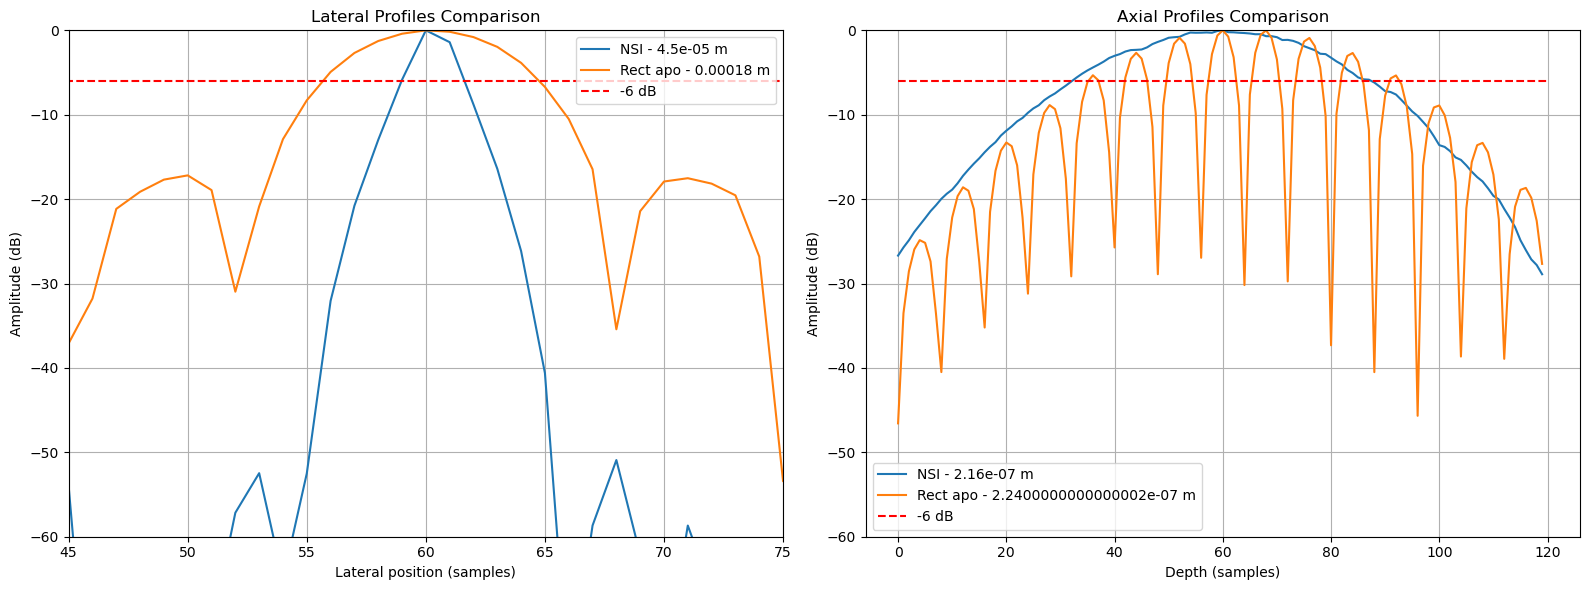

In [217]:
compare_resolutions(bf_matrix1, bf_matrix2, step_size, params["simulation"]["lateral_step"], submatrix_size=120, labels=["NSI", "Rect apo"], ymin=-60, ymax=0, xmin=45, xmax=75)